## Ideas
* use snpclust and pgkneo to rescue low hashtag score cells
* scrublet and doublet exclusion
* snp clust d5, merge neo p50exon, present neo vs snp cluster, 
* dc network
* look at index, feedback to Biolegend
* curate genes
* recount, integrate feature, aggregate

In [2]:
import scanpy as sc
import pandas as pd
import os
import seaborn as sns
import numpy as np

In [7]:
## Antibody tags
data3 = sc.read_mtx('../citeseq/d3AdtCount/umi_count/matrix.mtx.gz')
data3 = data3.T
features = pd.read_csv('../citeseq/d3AdtCount/umi_count/features.tsv.gz', header=None)
barcodes3 = pd.read_csv('../citeseq/d3AdtCount/umi_count/barcodes.tsv.gz', header=None)
data3.var_names = features[0]
data3.obs_names = barcodes3[0]

In [3]:
df = data3.to_df()

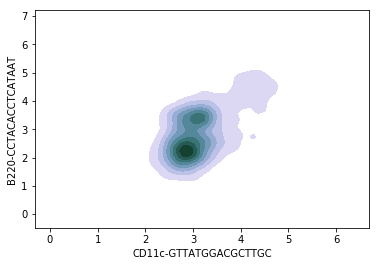

In [31]:
##Seaborn Plot 
cmap = sns.cubehelix_palette(start=2, light=1, as_cmap=True)
sns.kdeplot(np.log(df['CD11c-GTTATGGACGCTTGC']+1),np.log(df['B220-CCTACACCTCATAAT']+1), cmap = cmap, shade=True, shade_lowest=False)

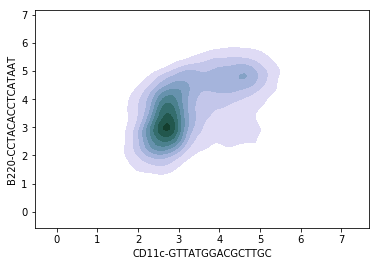

In [9]:
data5 = sc.read_mtx('../citeseq/d5AdtCount/umi_count/matrix.mtx.gz')
data5 = data5.T
features = pd.read_csv('../citeseq/d5AdtCount/umi_count/features.tsv.gz', header=None)
barcodes5 = pd.read_csv('../citeseq/d5AdtCount/umi_count/barcodes.tsv.gz', header=None)
data5.var_names = features[0]
data5.obs_names = barcodes5[0]
df = data5.to_df()
cmap = sns.cubehelix_palette(start=2, light=1, as_cmap=True)
sns.kdeplot(np.log(df['CD11c-GTTATGGACGCTTGC']+1),np.log(df['B220-CCTACACCTCATAAT']+1), cmap = cmap, shade=True, shade_lowest=False)

In [10]:
## Hashtag day 3
hash3 = sc.read_mtx('../citeseq/d3HtoCount/umi_count/matrix.mtx.gz')
hash3 = hash3.T
hashtags = pd.read_csv('../citeseq/d3HtoCount/umi_count/features.tsv.gz', header=None)
barcodes3 = pd.read_csv('../citeseq/d3HtoCount/umi_count/barcodes.tsv.gz', header=None)
hash3.var_names = hashtags[0]
hash3.obs_names = barcodes3[0]
# missing 30 cells

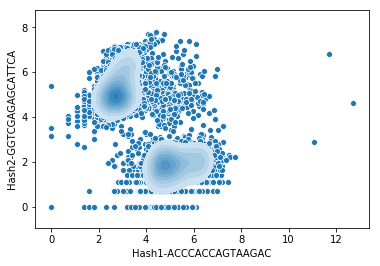

In [7]:
dfHash3 = hash3.to_df()
#dfHash3 = dfHash3.loc[dfHash3['Hash1-ACCCACCAGTAAGAC']<2980] ## remove 3 cells

## use diffratio to distinguish
#dfHash3['Max'] = dfHash3.max(axis=1)
#dfHash3['diff'] = dfHash3['Hash1-ACCCACCAGTAAGAC'] - dfHash3['Hash2-GGTCGAGAGCATTCA']
#dfHash3['diffRatio'] = dfHash3['diff'].abs()/dfHash3.Max
#dfHash3['diffRatio'].nsmallest(250)
sns.scatterplot(np.log(dfHash3['Hash1-ACCCACCAGTAAGAC']+1),np.log(dfHash3['Hash2-GGTCGAGAGCATTCA']+1))
sns.kdeplot(np.log(dfHash3['Hash1-ACCCACCAGTAAGAC']+1),np.log(dfHash3['Hash2-GGTCGAGAGCATTCA']+1),shade=True, shade_lowest=False)

In [11]:
# hastag day 5
hash5 = sc.read_mtx('../citeseq/d5HtoCount/umi_count/matrix.mtx.gz')
hash5 = hash5.T
hashtags = pd.read_csv('../citeseq/d5HtoCount/umi_count/features.tsv.gz', header=None)
barcodes5 = pd.read_csv('../citeseq/d5HtoCount/umi_count/barcodes.tsv.gz', header=None)
hash5.var_names = hashtags[0]
hash5.obs_names = barcodes5[0]
# missing 5 cells

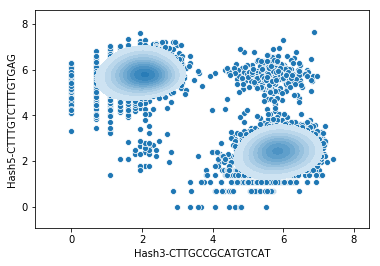

In [12]:
dfHash5 = hash5.to_df()
sns.scatterplot(np.log(dfHash5['Hash3-CTTGCCGCATGTCAT']+1),np.log(dfHash5['Hash5-CTTTGTCTTTGTGAG']+1))
sns.kdeplot(np.log(dfHash5['Hash3-CTTGCCGCATGTCAT']+1),np.log(dfHash5['Hash5-CTTTGTCTTTGTGAG']+1),shade=True, shade_lowest=False)

In [21]:
dfHash3.loc[(dfHash3['Hash1-ACCCACCAGTAAGAC']>55) & (dfHash3['Hash2-GGTCGAGAGCATTCA']>55)]
#338/8704
dfHash5.loc[(dfHash5['Hash3-CTTGCCGCATGTCAT']>55) & (dfHash5['Hash5-CTTTGTCTTTGTGAG']>55)]
#274/8510

,Hash1-ACCCACCAGTAAGAC,Hash2-GGTCGAGAGCATTCA,Hash3-CTTGCCGCATGTCAT,Hash4-AAAGCATTCTTCACG,Hash5-CTTTGTCTTTGTGAG,unmapped
0,,,,,,
GGCTTGGCAGAATGTA,0.0,1.0,332.0,0.0,366.0,58.0
AGGACGAGTGGAGAAA,0.0,0.0,276.0,0.0,546.0,94.0
CATGCAACATTAAAGG,0.0,0.0,194.0,0.0,270.0,49.0
GCATCTCCAACCACAT,0.0,0.0,400.0,1.0,1492.0,147.0
CCTGTTGTCTCTGCCA,0.0,0.0,268.0,0.0,207.0,53.0
...,...,...,...,...,...,...
CTACGGGAGCCATTTG,0.0,1.0,290.0,1.0,243.0,48.0
GTGTGGCGTCGCCACA,0.0,0.0,191.0,0.0,184.0,18.0
TGGGATTCACGGCGTT,0.0,1.0,327.0,2.0,260.0,28.0


In [11]:
oriCellsD3 = pd.read_csv('barcodes_d3.tsv', header=None)
oriCellsD5 = pd.read_csv('barcodes_d5.tsv', header=None)

,0
0,AAACCCAAGCTAAGTA-1
1,AAACCCACAACTTGGT-1
2,AAACCCACACAGAGCA-1
3,AAACCCAGTTACACAC-1
4,AAACCCAGTTCCGCAG-1
...,...
8510,TTTGTTGGTCCGGACT-1
8511,TTTGTTGGTGGTTTGT-1
8512,TTTGTTGTCATCGGGC-1
8513,TTTGTTGTCCAACCAA-1


In [12]:
dfD3ScrubletScore = pd.read_csv('/home/yi/scRNAseq/analysis/scrublet_d3.csv', index_col='barcodes')

In [13]:
dfD3ScrubletScore

,doublet_score,predicted_doublet
barcodes,,
AAACCCAAGAAGTGTT,0.013399,False
AAACCCAAGAATAGTC,0.012027,False
AAACCCAAGATTAGCA,0.027539,False
AAACCCAAGGATTACA,0.043832,False
AAACCCAAGTACCATC,0.019233,False
...,...,...
TTTGTTGTCAAGGAGC,0.019233,False
TTTGTTGTCACCGCTT,0.678082,True
TTTGTTGTCATTGGTG,0.012475,False


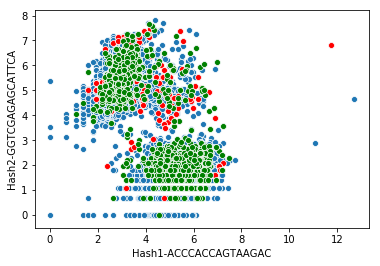

In [31]:
dfHash3Join = dfHash3.join(dfD3ScrubletScore)
dfHash3JoinTrue = dfHash3Join[dfHash3Join.predicted_doublet == True]
dfHash3JoinFlase = dfHash3Join[dfHash3Join.predicted_doublet == False]
dfHash3Removed = dfHash3Join[dfHash3Join.predicted_doublet.isna() ]
sns.scatterplot(np.log(dfHash3Join['Hash1-ACCCACCAGTAAGAC']+1),np.log(dfHash3Join['Hash2-GGTCGAGAGCATTCA']+1))
sns.scatterplot(np.log(dfHash3JoinTrue['Hash1-ACCCACCAGTAAGAC']+1),np.log(dfHash3JoinTrue['Hash2-GGTCGAGAGCATTCA']+1), color='r')
sns.scatterplot(np.log(dfHash3Removed['Hash1-ACCCACCAGTAAGAC']+1),np.log(dfHash3Removed['Hash2-GGTCGAGAGCATTCA']+1), color='g')
# #verify
# dfD3ScrubletScore.loc['GGTAATCGTTCTCAGA']


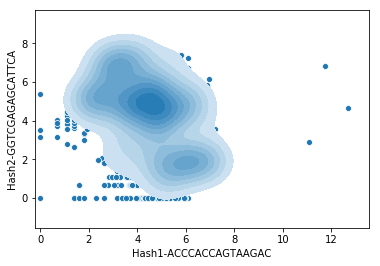

In [33]:
sns.scatterplot(np.log(dfHash3Join['Hash1-ACCCACCAGTAAGAC']+1),np.log(dfHash3Join['Hash2-GGTCGAGAGCATTCA']+1))
sns.kdeplot(np.log(dfHash3JoinTrue['Hash1-ACCCACCAGTAAGAC']+1),np.log(dfHash3JoinTrue['Hash2-GGTCGAGAGCATTCA']+1),shade=True, shade_lowest=False)

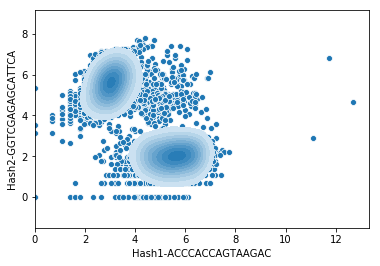

In [34]:
sns.scatterplot(np.log(dfHash3Join['Hash1-ACCCACCAGTAAGAC']+1),np.log(dfHash3Join['Hash2-GGTCGAGAGCATTCA']+1))
sns.kdeplot(np.log(dfHash3Removed['Hash1-ACCCACCAGTAAGAC']+1),np.log(dfHash3Removed['Hash2-GGTCGAGAGCATTCA']+1),shade=True, shade_lowest=False)

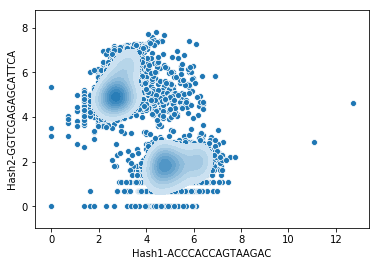

In [38]:
dfHash3JoinFalse = dfHash3Join[dfHash3Join.predicted_doublet == False]
sns.scatterplot(np.log(dfHash3JoinFalse['Hash1-ACCCACCAGTAAGAC']+1),np.log(dfHash3JoinFalse['Hash2-GGTCGAGAGCATTCA']+1))
sns.kdeplot(np.log(dfHash3JoinFalse['Hash1-ACCCACCAGTAAGAC']+1),np.log(dfHash3JoinFalse['Hash2-GGTCGAGAGCATTCA']+1),shade=True, shade_lowest=False)

## Day 5 scrublet view

In [3]:
dfD5ScrubletScore = pd.read_csv('/home/yi/scRNAseq/analysis/scrublet_d5.csv', index_col='barcodes')

In [4]:
dfD5ScrubletScore

,doublet_score,predicted_doublet
barcodes,,
AAACCCAAGCTAAGTA,0.042238,False
AAACCCACAACTTGGT,0.027059,False
AAACCCACACAGAGCA,0.036392,False
AAACCCAGTTACACAC,0.015884,False
AAACCCAGTTCCGCAG,0.027059,False
...,...,...
TTTGTTGGTATCCTTT,0.035330,False
TTTGTTGGTCCGGACT,0.025486,False
TTTGTTGTCATCGGGC,0.124563,False


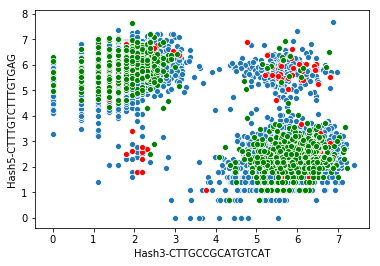

In [15]:
dfHash5Join = dfHash5.join(dfD5ScrubletScore)
dfHash5JoinTrue = dfHash5Join[dfHash5Join.predicted_doublet == True]
dfHash5JoinFalse = dfHash5Join[dfHash5Join.predicted_doublet == False]
dfHash5Removed = dfHash5Join[dfHash5Join.predicted_doublet.isna() ]
sns.scatterplot(np.log(dfHash5Join['Hash3-CTTGCCGCATGTCAT']+1),np.log(dfHash5Join['Hash5-CTTTGTCTTTGTGAG']+1))
sns.scatterplot(np.log(dfHash5JoinTrue['Hash3-CTTGCCGCATGTCAT']+1),np.log(dfHash5JoinTrue['Hash5-CTTTGTCTTTGTGAG']+1), color='r')
sns.scatterplot(np.log(dfHash5Removed['Hash3-CTTGCCGCATGTCAT']+1),np.log(dfHash5Removed['Hash5-CTTTGTCTTTGTGAG']+1), color='g')
# #verify
# dfD3ScrubletScore.loc['GGTAATCGTTCTCAGA']


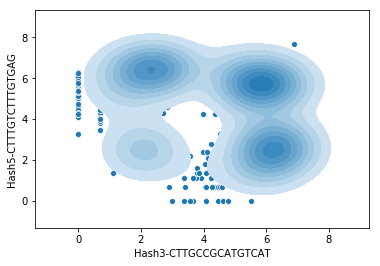

In [17]:
sns.scatterplot(np.log(dfHash5Join['Hash3-CTTGCCGCATGTCAT']+1),np.log(dfHash5Join['Hash5-CTTTGTCTTTGTGAG']+1))
sns.kdeplot(np.log(dfHash5JoinTrue['Hash3-CTTGCCGCATGTCAT']+1),np.log(dfHash5JoinTrue['Hash5-CTTTGTCTTTGTGAG']+1),shade=True, shade_lowest=False)

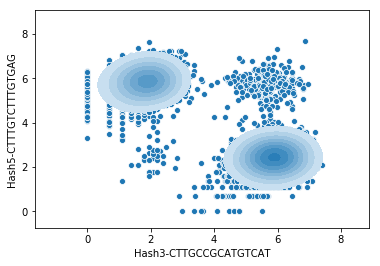

In [18]:
sns.scatterplot(np.log(dfHash5Join['Hash3-CTTGCCGCATGTCAT']+1),np.log(dfHash5Join['Hash5-CTTTGTCTTTGTGAG']+1))
sns.kdeplot(np.log(dfHash5Removed['Hash3-CTTGCCGCATGTCAT']+1),np.log(dfHash5Removed['Hash5-CTTTGTCTTTGTGAG']+1),shade=True, shade_lowest=False)

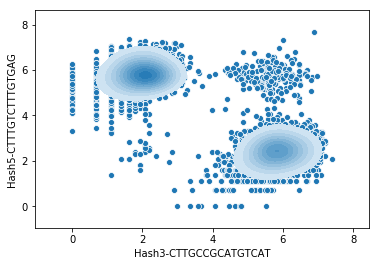

In [19]:
dfHash5JoinFalse = dfHash5Join[dfHash5Join.predicted_doublet == False]
sns.scatterplot(np.log(dfHash5JoinFalse['Hash3-CTTGCCGCATGTCAT']+1),np.log(dfHash5JoinFalse['Hash5-CTTTGTCTTTGTGAG']+1))
sns.kdeplot(np.log(dfHash5JoinFalse['Hash3-CTTGCCGCATGTCAT']+1),np.log(dfHash5JoinFalse['Hash5-CTTTGTCTTTGTGAG']+1),shade=True, shade_lowest=False)